<a href="https://colab.research.google.com/github/Destinywaya9/Wilson-Middleware/blob/main/Wilson_Zero_Selected_Simulations_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wilson-linked simulations — Zero RESULTS | Single Colab Run

**Original research, mathematics and ownership: Destiny Machwaya**  
**© 2015–2026 Destiny Machwaya. All rights reserved.**  
Lei A While Research Center: publication entity where applicable, not IP owner.

This one-run Colab companion combines five simulation modules from the Zero **QTET Colab Simulation Suite WITH RESULTS**: **#26 QRTM Phase-Correlation Cloud, #29 Wilson Branch Growth, #30 Unresolved Fragment Memory, #31 False-Context Rejection, and #32 Kernel vs Phenotype Growth**.

**Preservation:** Full, unchanged Tensor P2 reference `3,3 / 0,0 / 0,1 / 1,2 / 2,1 / 1,0 / 0,0 / Delay(200)`. The selected modules are *synthetic/architectural exploratory simulations*, not substituted Wilson architecture, IBM QPU runs, physical entropy measurements, or altered P2 operations.

**Source transparency:** Compiled from the readable **PDF export** of `QTET_Colab_Simulation_Suite_WITH_RESULTS.ipynb` because the original large notebook could not be retrieved through the connected GitHub reader. Simulation algorithms and default parameters are retained; necessary PDF text-wrap repairs and standalone dependencies are disclosed. This is **not** claimed to be a byte-identical extraction from the original `.ipynb`.

Original repository: https://github.com/Destinywaya9/ZERO  
**Run:** In Google Colab, open this notebook → Runtime → Run all. Figures, CSV files, and JSON provenance are saved automatically; a ZIP is produced for download. No IBM credentials or external AI models required.

In [1]:
# Install missing packages only.
import importlib.util, subprocess, sys
req={'numpy':'numpy','pandas':'pandas','matplotlib':'matplotlib','networkx':'networkx','scipy':'scipy','sklearn':'scikit-learn'}
missing=[pkg for mod,pkg in req.items() if importlib.util.find_spec(mod) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
print('Dependencies ready; installed:', missing or 'none')

Dependencies ready; installed: none


In [2]:
# Exact source kernel reference from Zero RESULTS; NO P2 implementation is changed.
import hashlib, json, zipfile
from collections import defaultdict
from datetime import datetime,timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy import signal
from sklearn.decomposition import PCA
from IPython.display import display
CANONICAL_P2=((3,3),(0,0),(0,1),(1,2),(2,1),(1,0),(0,0))
DELAY=200
P2_TOKENS=[f'{x},{y}' for x,y in CANONICAL_P2]+[f'Delay({DELAY})']
assert P2_TOKENS==['3,3','0,0','0,1','1,2','2,1','1,0','0,0','Delay(200)']
KERNEL_SHA256=hashlib.sha256(repr(CANONICAL_P2).encode('utf-8')).hexdigest()
assert KERNEL_SHA256=='e79eeab45fa25ae9663f40b7107248fa490d4bfb32fad283bc75ce2260de690e'
print('CANONICAL P2 REFERENCE VERIFIED:', ' / '.join(P2_TOKENS))
print('P2 reference SHA256:',KERNEL_SHA256)

CANONICAL P2 REFERENCE VERIFIED: 3,3 / 0,0 / 0,1 / 1,2 / 2,1 / 1,0 / 0,0 / Delay(200)
P2 reference SHA256: e79eeab45fa25ae9663f40b7107248fa490d4bfb32fad283bc75ce2260de690e


## 26 — QRTM Phase-Correlation Cloud

Synthetic bounded signals and phase-correlation profiles; does not replace the author's QRTM definition. The `signal.hilbert` transform here is signal processing, not a redefinition of zero or Hilbert-space closure.

In [3]:
def qrtm_phase_correlation_cloud(n_signals=40, samples=1800, seed=26, show=True):
    rng = np.random.default_rng(seed)
    t = np.linspace(0, 20, samples)
    signals = []
    for _ in range(n_signals):
        f = rng.uniform(0.7, 1.3)
        phase = rng.uniform(-np.pi, np.pi)
        amp = rng.uniform(0.7, 1.0)
        signals.append(amp * np.sin(2 * np.pi * f * t + phase))
    X = np.asarray(signals)
    phases = np.angle(signal.hilbert(X, axis=1))
    PLV = np.zeros((n_signals, n_signals))
    for i in range(n_signals):
        for j in range(n_signals):
            PLV[i, j] = abs(np.mean(np.exp(1j * (phases[i] - phases[j]))))
    coords = PCA(n_components=2).fit_transform(PLV)
    df = pd.DataFrame(coords, columns=['PC1', 'PC2'])
    df['mean_phase_correlation'] = PLV.mean(axis=1)
    if show:
        plt.scatter(df.PC1, df.PC2, c=df.mean_phase_correlation)
        plt.xlabel('PC1 of phase-correlation profile')
        plt.ylabel('PC2 of phase-correlation profile')
        plt.title('QRTM synthetic phase-correlation cloud')
        plt.colorbar(label='mean phase correlation')
        plt.show()
    return X, PLV, df

## 29 — Wilson Branch-Growth Simulation

Synthetic bucket/branch graph around a fixed P2 core. The source expressly calls this an architecture toy model, not the private Wilson implementation.

In [4]:
def wilson_branch_growth(n_fragments=300, seed=29, show=True):
    rng = np.random.default_rng(seed)
    topics = ['motion', 'sound', 'temperature', 'location', 'object', 'sequence']
    G = nx.DiGraph()
    G.add_node('P2_KERNEL', kind='fixed_kernel')
    for topic in topics:
        bucket = f'bucket:{topic}'
        G.add_edge('P2_KERNEL', bucket)
    for i in range(n_fragments):
        topic = rng.choice(topics)
        branch = f'branch:{topic}:{rng.integers(0, 6)}'
        fragment = f'fragment:{i}'
        G.add_edge(f'bucket:{topic}', branch)
        G.add_edge(branch, fragment)
    if show:
        pos = nx.spring_layout(G, seed=seed, k=0.25, iterations=70)
        plt.figure(figsize=(11, 9))
        nx.draw_networkx_edges(G, pos, alpha=0.12, width=0.5)
        nx.draw_networkx_nodes(G, pos, node_size=18)
        nx.draw_networkx_nodes(G, pos, nodelist=['P2_KERNEL'], node_size=350)
        plt.title('Wilson branch growth around fixed P2 core - architecture toy model')
        plt.axis('off')
        plt.show()
    return G

## 30 — Wilson Unresolved Fragment Memory

Source exploratory fragment-memory simulation with original default context count and seed.

In [5]:
def wilson_unresolved_memory(n_events=120, context_needed_demo=3, seed=30):
    rng = np.random.default_rng(seed)
    topics = ['A', 'B', 'C', 'D', 'E']
    unresolved = defaultdict(list)
    resolved = []
    timeline = []
    for i in range(n_events):
        topic = rng.choice(topics)
        fragment = f'f{i}:{topic}'
        unresolved[topic].append(fragment)
        if len(unresolved[topic]) >= context_needed_demo:
            resolved.extend(unresolved[topic])
            unresolved[topic] = []
        timeline.append({
            'event': i, 'topic': topic,
            'resolved_total': len(resolved),
            'unresolved_total': sum(len(v) for v in unresolved.values()),
        })
    return pd.DataFrame(timeline), unresolved, resolved

## 31 — Wilson False-Context Rejection

The source labels the overlap score and `threshold_demo` as **simulation controls, not canonical Wilson rules**. The original PDF cuts off the end of the `.sort_values` line; `ascending=False` below restores its recorded descending-score result.

In [6]:
def wilson_false_context_rejection(query_tokens, candidates, threshold_demo=0.5):
    q = set(query_tokens)
    rows = []
    for name, tokens in candidates.items():
        s = set(tokens)
        union = q | s
        score = len(q & s) / len(union) if union else 0.0
        rows.append((name, score, score >= threshold_demo))
    return pd.DataFrame(rows, columns=['candidate', 'toy_overlap_score', 'accepted_under_demo_rule']).sort_values('toy_overlap_score', ascending=False)

## 32 — Kernel vs Phenotype Growth

Growth of a synthetic higher-level graph while retaining the **original unchanged P2 reference hash**.

In [7]:
def _kernel_hash():
    payload = repr(CANONICAL_P2).encode('utf-8')
    return hashlib.sha256(payload).hexdigest()

def kernel_vs_phenotype_growth(observations=1000, seed=32, show=True):
    rng = np.random.default_rng(seed)
    kernel_hash = _kernel_hash()
    nodes = 1
    edges = 0
    rows = []
    for t in range(observations):
        if rng.random() < 0.35:
            nodes += 1
            edges += int(rng.integers(1, 4))
        if t % max(1, observations // 100) == 0:
            rows.append((t, nodes, edges, kernel_hash))
    df = pd.DataFrame(rows, columns=['observation', 'phenotype_nodes', 'phenotype_edges', 'kernel_sha256'])
    if show:
        plt.plot(df.observation, df.phenotype_nodes, label='phenotype nodes')
        plt.plot(df.observation, df.phenotype_edges, label='phenotype edges')
        plt.xlabel('environmental observations')
        plt.ylabel('graph size')
        plt.title('Fixed kernel vs growing synthetic phenotype')
        plt.legend()
        plt.show()
    return df

## Run all five source simulations and export results

The following cell runs the five defined simulations with their **original defaults**. It adds only a figure-saving wrapper and provenance manifest. It checks the printed-results values against the Zero RESULTS PDF export and verifies that the canonical P2 reference remains unchanged.

1/5 - QRTM Phase-Correlation Cloud (Zero RESULTS #26)


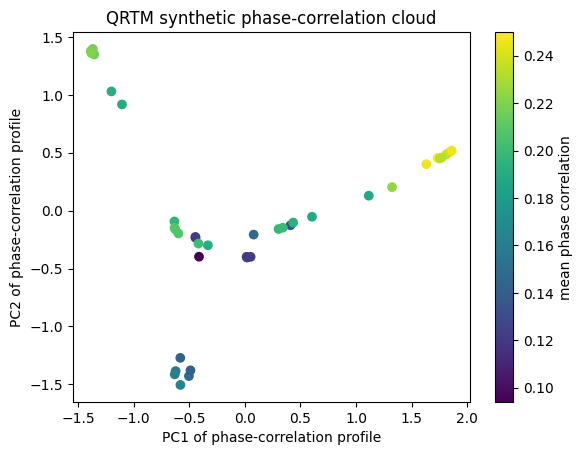

Phase-correlation matrix shape: (40, 40)
2/5 - Wilson Branch-Growth (Zero RESULTS #29)


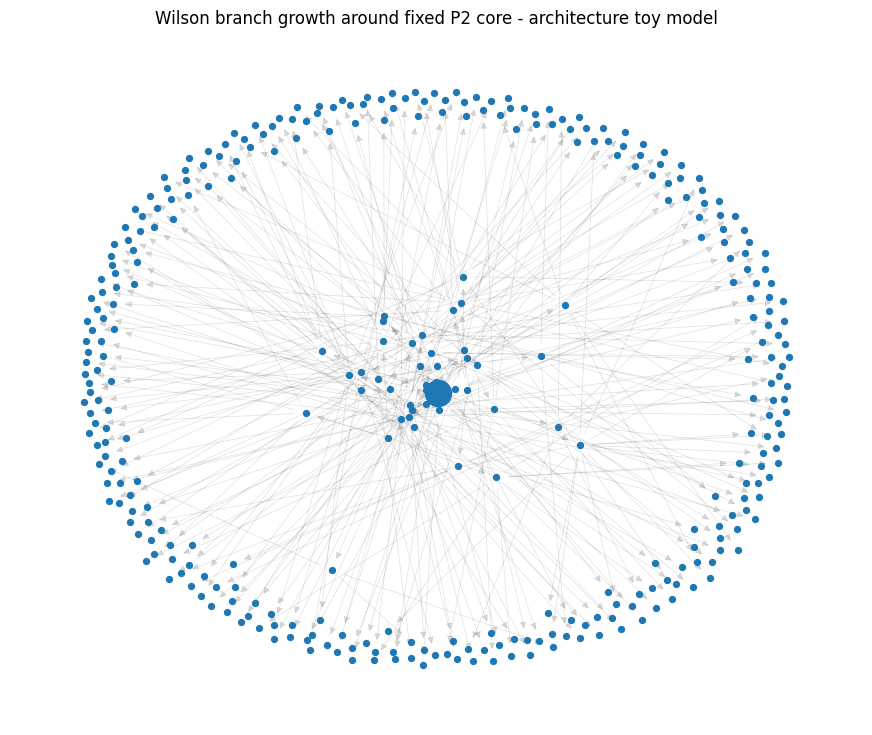

Graph nodes / edges: 343 342
3/5 - Wilson Unresolved Fragment Memory (Zero RESULTS #30)


,event,topic,resolved_total,unresolved_total
115,115,D,111,5
116,116,C,114,3
117,117,B,114,4
118,118,C,114,5
119,119,C,114,6


4/5 - Wilson False-Context Rejection (Zero RESULTS #31)


,candidate,toy_overlap_score,accepted_under_demo_rule
0,context_A,1.0,True
2,context_C,0.5,True
1,context_B,0.0,False


5/5 - Kernel vs Phenotype Growth (Zero RESULTS #32)


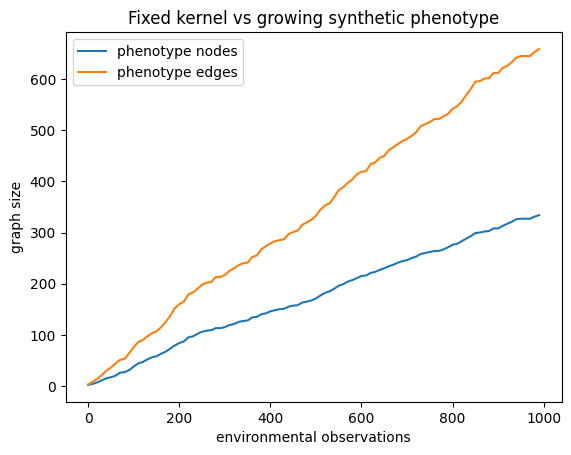

,observation,phenotype_nodes,phenotype_edges,kernel_sha256
95,950,327,645,e79eeab45fa25ae9663f40b7107248fa490d4bfb32fad2...
96,960,327,645,e79eeab45fa25ae9663f40b7107248fa490d4bfb32fad2...
97,970,327,645,e79eeab45fa25ae9663f40b7107248fa490d4bfb32fad2...
98,980,331,653,e79eeab45fa25ae9663f40b7107248fa490d4bfb32fad2...
99,990,334,659,e79eeab45fa25ae9663f40b7107248fa490d4bfb32fad2...


ALL FIVE COMPLETE; P2 REFERENCE UNCHANGED
Saved figures: ['26_qrtm_phase_correlation_cloud.png', '29_wilson_branch_growth.png', '32_kernel_vs_phenotype_growth.png']
Data folder: /content/wilson_zero_selected_simulations_outputs
Data ZIP: /content/Wilson_Zero_Selected_Simulations_Results.zip


In [8]:
OUTPUT_DIR=Path('wilson_zero_selected_simulations_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
SOURCE_PDF_SHA256='22fca0878911cc8112813216ad9012034ae94135220a3db3be40a66ae7416fdc'
SAVED_PLOTS=[]

# Figure interception only: simulation functions and mathematics are untouched.
def with_saved_plot(filename, func, *args, **kwargs):
    original_show=plt.show
    def save_then_show(*show_args, **show_kwargs):
        fig=plt.gcf()
        path=OUTPUT_DIR/filename
        fig.savefig(path,dpi=160,bbox_inches='tight')
        SAVED_PLOTS.append(path.name)
        return original_show(*show_args,**show_kwargs)
    plt.show=save_then_show
    try:
        return func(*args,**kwargs)
    finally:
        plt.show=original_show

print('1/5 - QRTM Phase-Correlation Cloud (Zero RESULTS #26)')
X,PLV,phase_df=with_saved_plot('26_qrtm_phase_correlation_cloud.png',qrtm_phase_correlation_cloud)
phase_df.to_csv(OUTPUT_DIR/'26_qrtm_phase_correlation_cloud.csv',index=False)
pd.DataFrame(PLV).to_csv(OUTPUT_DIR/'26_qrtm_phase_locking_matrix.csv',index=False)
print('Phase-correlation matrix shape:',PLV.shape)

print('2/5 - Wilson Branch-Growth (Zero RESULTS #29)')
G_wilson=with_saved_plot('29_wilson_branch_growth.png',wilson_branch_growth)
pd.DataFrame(G_wilson.edges(),columns=['source','target']).to_csv(OUTPUT_DIR/'29_wilson_branch_edges.csv',index=False)
print('Graph nodes / edges:',G_wilson.number_of_nodes(),G_wilson.number_of_edges())

print('3/5 - Wilson Unresolved Fragment Memory (Zero RESULTS #30)')
timeline,unresolved,resolved=wilson_unresolved_memory()
timeline.to_csv(OUTPUT_DIR/'30_wilson_fragment_timeline.csv',index=False)
display(timeline.tail())

print('4/5 - Wilson False-Context Rejection (Zero RESULTS #31)')
demo_candidates={
    'context_A':['motion','object','left'],
    'context_B':['temperature','warm','room'],
    'context_C':['motion','object','right'],
}
context_df=wilson_false_context_rejection(['motion','object','left'],demo_candidates)
context_df.to_csv(OUTPUT_DIR/'31_wilson_false_context_rejection.csv',index=False)
display(context_df)

print('5/5 - Kernel vs Phenotype Growth (Zero RESULTS #32)')
phenotype_df=with_saved_plot('32_kernel_vs_phenotype_growth.png',kernel_vs_phenotype_growth)
phenotype_df.to_csv(OUTPUT_DIR/'32_kernel_vs_phenotype_growth.csv',index=False)
display(phenotype_df.tail())

# Regression checks against the saved results in the Zero RESULTS PDF export.
assert (G_wilson.number_of_nodes(),G_wilson.number_of_edges())==(343,342)
assert len(resolved)==114 and sum(map(len,unresolved.values()))==6
assert list(context_df.candidate)==['context_A','context_C','context_B']
assert all(phenotype_df.kernel_sha256==KERNEL_SHA256)
assert P2_TOKENS==['3,3','0,0','0,1','1,2','2,1','1,0','0,0','Delay(200)']

manifest={
    'title':'Wilson-linked Zero RESULTS - five standalone exploratory simulations',
    'author_and_owner':'Destiny Machwaya',
    'copyright':'Copyright (c) 2015-2026 Destiny Machwaya. All rights reserved.',
    'generated_utc':datetime.now(timezone.utc).isoformat(),
    'source_url':'https://github.com/Destinywaya9/ZERO/blob/main/QTET_Colab_Simulation_Suite_WITH_RESULTS.ipynb',
    'source_pdf_title':'QTET_Colab_Simulation_Suite_WITH_RESULTS.ipynb - Colab.pdf',
    'source_pdf_sha256':SOURCE_PDF_SHA256,
    'source_transcription':'PDF export (standalone reconstruction with PDF line-wrap repair; not byte-identical original notebook)',
    'selected_source_sections':[26,29,30,31,32],
    'exact_p2_tokens':P2_TOKENS,
    'canonical_numeric_reference_sha256':KERNEL_SHA256,
    'p2_modified':False,
    'ibm_qpu_jobs_performed':0,
    'results':{
        'phase_correlation_matrix_shape':list(PLV.shape),
        'branch_growth_nodes':G_wilson.number_of_nodes(),
        'branch_growth_edges':G_wilson.number_of_edges(),
        'fragment_resolved':len(resolved),
        'fragment_unresolved':sum(map(len,unresolved.values())),
        'false_context_demo_scores':{row.candidate:float(row.toy_overlap_score) for row in context_df.itertuples()},
        'phenotype_final_nodes':int(phenotype_df.iloc[-1].phenotype_nodes),
        'phenotype_final_edges':int(phenotype_df.iloc[-1].phenotype_edges),
    },
    'saved_figures':SAVED_PLOTS,
}
(OUTPUT_DIR/'PROVENANCE_MANIFEST.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
BUNDLE_NAME='Wilson_Zero_Selected_Simulations_Results.zip'
with zipfile.ZipFile(BUNDLE_NAME,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUTPUT_DIR.glob('*')):
        if p.is_file():z.write(p,arcname=f'{OUTPUT_DIR.name}/{p.name}')
print('ALL FIVE COMPLETE; P2 REFERENCE UNCHANGED')
print('Saved figures:',SAVED_PLOTS)
print('Data folder:',OUTPUT_DIR.resolve())
print('Data ZIP:',Path(BUNDLE_NAME).resolve())

### Export guidance

**Export both**: keep the executed `.ipynb` (reproducible source and in-notebook figures) and a PDF export of the displayed plots for a fixed visual record. The saved PNGs, CSVs, and provenance JSON are bundled into `Wilson_Zero_Selected_Simulations_Results.zip` by the final code cell. This output is not a new Tensor P2 law, Wilson implementation, or IBM QPU experiment.

For Colab results ZIP download, execute the optional cell after the run, or use the Colab file browser.

In [9]:
# OPTIONAL - uncomment to download ZIP from Google Colab after Run all.
# from google.colab import files
# files.download('Wilson_Zero_Selected_Simulations_Results.zip')